In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Para el proyecto cuyo cuadro de prelaciones se adjunta se manejan tres escenarios de duración de las actividades (en días): optimista, normal y pesimista. Se quiere conocer la duración del proyecto en los tres sin repetir tres veces el cálculo de tiempos.

In [3]:
pregunta_1 = "1. Dibuje el grafo PERT y construya la matriz de caminos R.  "
pregunta_2 = "2. Disponga los tres escenarios como columnas de una matriz T (una fila por actividad) y calcule el producto R·T. ¿Qué representa cada columna del resultado?  "
pregunta_3 = "3. Obtenga la duración del proyecto en cada escenario como el máximo de cada columna, e indique la ruta crítica de cada uno. ¿Es siempre la misma?  "
pregunta_4 = "4. ¿Por qué este procedimiento es el mismo que se usa en el método de Monte Carlo?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo PERT y construya la matriz de caminos R.  

2. Disponga los tres escenarios como columnas de una matriz T (una fila por actividad) y calcule el producto R·T. ¿Qué representa cada columna del resultado?  

3. Obtenga la duración del proyecto en cada escenario como el máximo de cada columna, e indique la ruta crítica de cada uno. ¿Es siempre la misma?  

4. ¿Por qué este procedimiento es el mismo que se usa en el método de Monte Carlo?  

In [4]:
#| tbl-cap: "Cuadro de prelaciones"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('A'     , '---'      ),
    ('B'     , '---'      ),
    ('C'     , '---'      ),
    ('D'     , 'A,C'      ),
    ('E'     , 'B,C'      ),
    ('F'     , 'D'        ),
    ('G'     , 'E'        ),
    ('H'     , 'F,G'      ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
A,---
B,---
C,---
D,"A,C"
E,"B,C"
F,D
G,E
H,"F,G"


El proyecto corresponde a la rehabilitación de una nave industrial para un taller; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Levantamiento topográfico y mediciones',
    'B': 'Proyecto de ejecución y licencia',
    'C': 'Desmontaje de instalaciones antiguas',
    'D': 'Demolición de tabiquería interior',
    'E': 'Refuerzo de la estructura metálica',
    'F': 'Reparación de la cubierta',
    'G': 'Solera y canalizaciones',
    'H': 'Cerramientos y carpintería exterior',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Levantamiento topográfico y mediciones
B,Proyecto de ejecución y licencia
C,Desmontaje de instalaciones antiguas
D,Demolición de tabiquería interior
E,Refuerzo de la estructura metálica
F,Reparación de la cubierta
G,Solera y canalizaciones
H,Cerramientos y carpintería exterior


In [6]:
#| tbl-cap: "Escenarios de duración (días)"
#| label: tbl-escenarios
escenarios = pd.DataFrame([
#  activity, optimista, normal, pesimista
    ('A'     , 3        , 4     , 7        ),
    ('B'     , 2        , 2     , 3        ),
    ('C'     , 3        , 3     , 4        ),
    ('D'     , 2        , 3     , 4        ),
    ('E'     , 8        , 8     , 10       ),
    ('F'     , 1        , 2     , 3        ),
    ('G'     , 7        , 8     , 11       ),
    ('H'     , 5        , 6     , 9        ),
], columns=['activity', 'optimista', 'normal', 'pesimista']).set_index('activity')
escenarios

,optimista,normal,pesimista
activity,,,
A,3,4,7
B,2,2,3
C,3,3,4
D,2,3,4
E,8,8,10
F,1,2,3
G,7,8,11
H,5,6,9


# Resolución

In [7]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

In [8]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Dibuje el grafo PERT y construya la matriz de caminos R.  

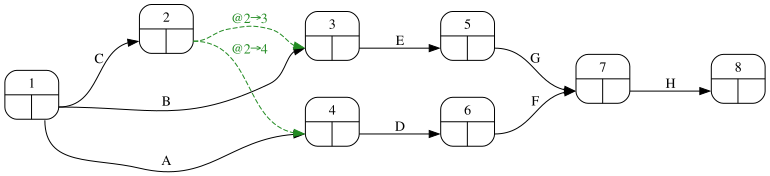

In [10]:
#| fig-cap: "Grafo PERT"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)

In [11]:
#| tbl-cap: "Matriz de caminos"
#| label: tbl-matrizCaminos
R = proyecto.path_matrix(dummies=False)
proyecto.display_path_matrix(dummies=False)

,A,B,C,D,E,F,G,H
Route_1,1,0,0,1,0,1,0,1
Route_2,0,1,0,0,1,0,1,1
Route_3,0,0,1,1,0,1,0,1
Route_4,0,0,1,0,1,0,1,1


## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Disponga los tres escenarios como columnas de una matriz T (una fila por actividad) y calcule el producto R·T. ¿Qué representa cada columna del resultado?  

In [13]:
T = escenarios.loc[R.columns]
duraciones_rutas = R @ T
Math(bmatrix(R) + r' \times ' + bmatrix(T) + ' = ' + bmatrix(duraciones_rutas))

<IPython.core.display.Math object>

In [14]:
#| tbl-cap: "Duración de cada ruta en cada escenario"
#| label: tbl-duracionesRutas
duraciones_rutas

,optimista,normal,pesimista
Route_1,11,15,23
Route_2,22,24,33
Route_3,11,14,20
Route_4,23,25,34


Cada columna de R·T es el vector de duraciones de las rutas para un escenario: la fila r, columna s, es la suma de las duraciones (en el escenario s) de las actividades de la ruta r.

## Apartado 3

In [15]:
display(Markdown(pregunta_3))

3. Obtenga la duración del proyecto en cada escenario como el máximo de cada columna, e indique la ruta crítica de cada uno. ¿Es siempre la misma?  

In [16]:
resumen = pd.DataFrame({'duración del proyecto': duraciones_rutas.max(), 'ruta crítica': duraciones_rutas.idxmax()})
resumen['actividades'] = [' - '.join(R.columns[R.loc[r] == 1]) for r in resumen['ruta crítica']]
resumen

,duración del proyecto,ruta crítica,actividades
optimista,23,Route_4,C - E - G - H
normal,25,Route_4,C - E - G - H
pesimista,34,Route_4,C - E - G - H


In [17]:
Markdown('La ruta crítica ' + ('es la misma en los tres escenarios.' if resumen['ruta crítica'].nunique() == 1 else 'cambia de un escenario a otro: la ruta más larga depende de las duraciones, no sólo de la forma del grafo.'))

La ruta crítica es la misma en los tres escenarios.

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. ¿Por qué este procedimiento es el mismo que se usa en el método de Monte Carlo?  

En Monte Carlo cada réplica es un escenario: la matriz T tiene una columna por réplica (miles de columnas) y R·T da de una vez la duración de todas las rutas en todas las réplicas; el máximo de cada columna es la duración del proyecto en esa réplica. Con tres columnas el cálculo se hace a mano; con diez mil lo hace el ordenador, pero la operación es idéntica.